In [216]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GCNConv, GAE
import pandas as pd
import numpy as np
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import MinMaxScaler
from torch_geometric.utils import from_scipy_sparse_matrix
from torch_geometric.data import Data
import scipy.sparse as sp
import networkx as nx
import matplotlib.pyplot as plt
from torch.nn import BatchNorm1d
from sklearn.metrics import roc_auc_score, average_precision_score, precision_score, recall_score, f1_score
import torch
import torch.nn.functional as F
from torch_geometric.nn import GCNConv
from torch.nn import BatchNorm1d
from torch_geometric.utils import dropout_adj
import random
from torch.nn import LayerNorm
import torch
import torch.nn.functional as F
from torch_geometric.nn import GCNConv, BatchNorm
import numpy as np
import pandas as pd
import scipy.sparse as sp
from torch_geometric.data import Data
from torch_geometric.nn import GAE
from torch_geometric.utils import from_scipy_sparse_matrix


random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# Load the data
#data = pd.read_csv("/Users/nirwantandukar/input_data/SAP_lipids/NORMALIZED_EXP/normalized_weight_matrix_SAP_lowinput_0.2filter.csv", index_col=0)
#data = pd.read_csv("/Users/nirwantandukar/input_data/Database.DREAM4/NORMALIZED_EXP/normalized_weight_matrix_all_GRN_100_01_0.2filter.csv", index_col=0)
#data = pd.read_csv("/Users/nirwantandukar/input_data/PSU_P/NORMALIZED_EXP/normalized_weight_matrix_All_sig_genes_MaSigPro_NB_exp0.2filter.csv", index_col=0)
#data = pd.read_csv("/Users/nirwantandukar/input_data/GRN_R/adj_matrices_DREAM4_03_100_02filter_GRN_in_R_normalized.csv", index_col=0)
#data = pd.read_csv("/Users/nirwantandukar/input_data/individual_GRNs/Combined_GRN_horizontal_matrix.csv", index_col=0)
#data = pd.read_csv(
#    "/Users/nirwantandukar/input_data/e_coli/NORMALIZED_EXP/adj_matrices_ecoli_net3_02filter_GRN_in_R_normalized.csv",
#    
#    index_col=0  # First column is the index
#)
data = pd.read_csv("/Users/nirwantandukar/input_data/Database.DREAM4/NORMALIZED_EXP/normalized_weight_matrix_all_GRN_100_01_0.2filter.csv", index_col=0)
#data = pd.read_csv("/Users/nirwantandukar/input_data/maize_lowhighN/NORMALIZED_EXP/normalized_weight_matrix_highlowN_B73_exp_0.2filter.csv", index_col=0)
#data = pd.read_csv("/Users/nirwantandukar/input_data/PSU_P/NORMALIZED_EXP/normalized_weight_matrix_All_sig_genes_MaSigPro_NB_exp0.2filter.csv", index_col=0)
print(f"Loaded data with shape: {data.shape}")

# Get the list of algorithms
columns = data.columns
algorithms = sorted(set(col.split('.')[0] for col in columns))
print(f"Algorithms found: {algorithms}")

num_genes = data.shape[0]
gene_names = data.index.tolist()
print(f"Number of genes: {num_genes}")

# Node features (identity matrix)
node_features = np.identity(num_genes)
print(f"Node features shape: {node_features.shape}")

# Functions
# Functions
class GCNEncoder(torch.nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels, num_layers=3, dropout_rate=0.5, edge_dropout_rate=0.5):
    #def __init__(self, in_channels, hidden_channels, out_channels, num_layers=3, dropout_rate=0.1, edge_dropout_rate=0.1):
        super(GCNEncoder, self).__init__()
        self.num_layers = num_layers
        self.dropout_rate = dropout_rate
        self.edge_dropout_rate = edge_dropout_rate
        
        # First layer: input to 2x hidden size
        self.convs = torch.nn.ModuleList()
        self.convs.append(GCNConv(in_channels, 2 * hidden_channels, cached=False))
        
        # Add intermediate layers
        for _ in range(num_layers - 2):
            self.convs.append(GCNConv(2 * hidden_channels, 2 * hidden_channels, cached=False))
        
        # Final layer: hidden size to output size
        self.convs.append(GCNConv(2 * hidden_channels, out_channels, cached=False))
    
        # Batch normalization layers for each convolution layer
        #self.bns = torch.nn.ModuleList([BatchNorm1d(2 * hidden_channels) for _ in range(num_layers - 1)])
        self.bns = torch.nn.ModuleList([BatchNorm1d(2 * hidden_channels, momentum=0.1) for _ in range(num_layers - 1)])

    
        # Dropout rate
        self.dropout = torch.nn.Dropout(p=dropout_rate)
    
        # LeakyReLU instead of ReLU
        #self.activation = torch.nn.LeakyReLU(negative_slope=0.05)
        #self.activation = torch.nn.Sigmoid()
        #self.activation_hidden = torch.nn.LeakyReLU(negative_slope=0.05)  # For hidden layers
        self.activation_hidden = torch.nn.ReLU  # For hidden layers
        self.activation_output = torch.nn.Sigmoid()  # For final layer


    
    def forward(self, x, edge_index):
        # Apply edge dropout
        edge_index, _ = dropout_adj(edge_index, p=self.edge_dropout_rate, training=self.training)
        
        # First layer (without batch normalization)
        x = self.convs[0](x, edge_index)
        #x = self.activation_hidden(x)
        x = F.relu(x)
    
    # Intermediate layers with batch normalization and dropout
        for i in range(1, self.num_layers - 1):
            x_residual = x # For residual connection
            x = self.convs[i](x, edge_index)
            x = self.bns[i-1](x) # Apply batch normalization
            #x = self.activation_hidden(x)
            x = F.relu(x)
            x = self.dropout(x)
            
            # Add residual connection (skip connection)
            x = x + x_residual
    
        # Final layer (no activation or batch norm)
        x = self.convs[-1](x, edge_index)
        x = F.relu(x)
        #x = self.activation_output(x)
        return x



#normalized_laplacian
def normalize_adj(adj):
    """Compute the normalized Laplacian."""
    adj = sp.coo_matrix(adj)
    rowsum = np.array(adj.sum(1)).flatten()
    d_inv_sqrt = np.power(rowsum + 1e-5, -0.5)
    d_inv_sqrt[np.isinf(d_inv_sqrt)] = 0.0
    d_mat_inv_sqrt = sp.diags(d_inv_sqrt)
    identity = sp.eye(adj.shape[0])  # Identity matrix of the same size as adj
    laplacian = identity - d_mat_inv_sqrt.dot(adj).dot(d_mat_inv_sqrt)  # Normalized Laplacian
    return laplacian.tocoo()




# Convert ground truth matrix to edge list (undirected)
def convert_matrix_to_edge_list(matrix):
    edges = set()  # Use a set to avoid duplicates
    for source in matrix.index:
        for target in matrix.columns:
            if matrix.at[source, target] == 1 and source != target:  # Exclude self-loops
                edge = tuple(sorted([source, target]))  # Sort to ensure undirected representation
                edges.add(edge)
    return edges


# Define the function to perform the GAE process for each threshold and multiple iterations
def run_gae_multiple_thresholds(data, algorithms, thresholds, num_iterations=30):
    num_genes = data.shape[0]
    all_results = {}
    iteration_sums = {}

    for threshold in thresholds:
        print(f"Running for threshold: {threshold}")
        
        # Create a dictionary to store the results for each algorithm and threshold
        all_results[f'threshold_{threshold}'] = {}
        iteration_sums[f'threshold_{threshold}'] = {}

        # Initialize the iteration sum matrices for each threshold
        for iter_num in range(num_iterations):
            iteration_sums[f'threshold_{threshold}'][f'iter{iter_num + 1}_GCN_sum'] = np.zeros((num_genes, num_genes))

        for alg in algorithms:
            print(f"Running GAE for algorithm: {alg} with threshold: {threshold}")
            alg_columns = [col for col in data.columns if col.startswith(alg + '.')]
            alg_matrix = data[alg_columns].values

            # For each algorithm, create a list to store multiple runs
            all_results[f'threshold_{threshold}'][alg] = []

            for iteration in range(num_iterations):
                print(f"Iteration {iteration + 1}/{num_iterations} for algorithm: {alg}")
                
                # Apply GAE to the adjacency matrix of the algorithm
                adj_reconstructed = apply_gae_to_adjacency(alg_matrix, node_features)
                
                # Binarize the reconstructed adjacency matrix using the current threshold
                adj_binary = (adj_reconstructed > threshold).astype(int)

                # Store the binary adjacency matrix for this run
                all_results[f'threshold_{threshold}'][alg].append(adj_binary)

                # Add the binary matrix to the sum for this iteration and threshold
                iteration_sums[f'threshold_{threshold}'][f'iter{iteration + 1}_GCN_sum'] += adj_binary

    return all_results, iteration_sums


# Function to extract nodes and edges from the binary matrix
def count_nodes_edges(final_matrix):
    # Count edges in the upper triangle (to avoid double counting for undirected graphs)
    num_edges = np.sum(np.triu(final_matrix, k=1))
    
    # Count nodes (genes with at least one edge, i.e., rows/columns with non-zero values)
    connected_nodes = np.sum(np.any(final_matrix, axis=1))  # Count rows with non-zero values
    num_nodes = connected_nodes
    
    return num_nodes, num_edges


# Function to apply a second binarization threshold to the summed adjacency matrices
def apply_iteration_threshold(iteration_sums, thresholds, iter_thresholds):
    binary_sums = {}
    
    for threshold in thresholds:
        binary_sums[f'threshold_{threshold}'] = {}
        for iter_num in iteration_sums[f'threshold_{threshold}'].keys():
            binary_sums[f'threshold_{threshold}'][iter_num] = {}

            for iter_threshold in iter_thresholds:
                print(f"Applying iter_threshold {iter_threshold} to {iter_num} for threshold {threshold}")
                
                # Apply binarization on the summed adjacency matrix
                summed_matrix = iteration_sums[f'threshold_{threshold}'][iter_num]
                binary_matrix = (summed_matrix >= iter_threshold).astype(int)

                # Store the result
                binary_sums[f'threshold_{threshold}'][iter_num][f'iter_threshold_{iter_threshold}'] = binary_matrix
    
    return binary_sums


# Function to sum across iterations and apply a common threshold
def sum_across_iterations_and_binarize(binary_summed_matrices, thresholds, iter_thresholds, common_threshold):
    common_sums = {}

    for threshold in thresholds:
        common_sums[f'threshold_{threshold}'] = {}
        for iter_threshold in iter_thresholds:
            print(f"Summing across iterations for threshold {threshold} and iter_threshold {iter_threshold}")

            # Initialize the matrix for summing across iterations
            iteration_sum_matrix = np.zeros_like(binary_summed_matrices[f'threshold_{threshold}']['iter1_GCN_sum'][f'iter_threshold_{iter_threshold}'])

            # Sum the matrices across all iterations
            for iter_num in binary_summed_matrices[f'threshold_{threshold}'].keys():
                iteration_sum_matrix += binary_summed_matrices[f'threshold_{threshold}'][iter_num][f'iter_threshold_{iter_threshold}']

            # Apply the common threshold: if sum >= common_threshold, set 1; else set 0
            final_binarized_matrix = (iteration_sum_matrix >= common_threshold).astype(int)

            # Store the result
            common_sums[f'threshold_{threshold}'][f'iter_threshold_{iter_threshold}_common_threshold_{common_threshold}'] = final_binarized_matrix

    return common_sums



# Function to extract gene interactions (edges) from a binarized matrix
def extract_gene_interactions(final_matrix, gene_names):
    edges = []
    num_genes = final_matrix.shape[0]

    # Loop through the upper triangle of the matrix to avoid duplicates (since it's undirected)
    for i in range(num_genes):
        for j in range(i + 1, num_genes):
            if final_matrix[i, j] == 1:  # Check if there's an interaction
                edges.append(f"{gene_names[i]}-{gene_names[j]}")
    
    return edges


# Example to count nodes and edges for each threshold
def count_nodes_edges_for_thresholds(binary_summed_matrices, thresholds, iter_thresholds, common_threshold):
    node_edge_counts = {}

    for threshold in thresholds:
        for iter_threshold in iter_thresholds:
            final_matrix = binary_summed_matrices[f'threshold_{threshold}'][f'iter_threshold_{iter_threshold}_common_threshold_{common_threshold}']
            
            # Count nodes and edges
            num_nodes, num_edges = count_nodes_edges(final_matrix)
            
            # Store the counts
            node_edge_counts[f'threshold_{threshold}_iter_threshold_{iter_threshold}'] = {
                'Nodes': num_nodes,
                'Edges': num_edges
            }
    
    return node_edge_counts


# GAE model with weight decay and dropout
def apply_gae_to_adjacency(adj_matrix, node_features, embedding_dim=10, epochs=200, dropout_rate=0.5, edge_dropout_rate=0.1, weight_decay=1e-4, early_stopping=True, patience=20):
    from sklearn.preprocessing import StandardScaler
    from tqdm import tqdm
    import torch.nn.utils

    # Normalize node features
    scaler = StandardScaler()
    node_features = scaler.fit_transform(node_features)

    # Convert adjacency matrix to sparse format and normalize
    adj_sparse = sp.csr_matrix(adj_matrix)
    adj_normalized = normalize_adj(adj_sparse + sp.eye(adj_sparse.shape[0]))
    edge_index, edge_weight = from_scipy_sparse_matrix(adj_normalized)

    # Create data object
    x = torch.tensor(node_features, dtype=torch.float)
    data = Data(x=x, edge_index=edge_index)

    # Define encoder and model
    encoder = GCNEncoder(in_channels=x.shape[1], hidden_channels=embedding_dim, out_channels=embedding_dim, dropout_rate=dropout_rate, edge_dropout_rate=edge_dropout_rate)
    model = GAE(encoder)

    # Device setup
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model = model.to(device)
    data = data.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=10, verbose=True)

    # Training loop
    model.train()
    best_loss = float('inf')
    patience_counter = 0
    for epoch in tqdm(range(1, epochs + 1), desc="Training"):
        optimizer.zero_grad()
        z = model.encode(data.x, data.edge_index)
        loss = model.recon_loss(z, data.edge_index)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step(loss)

        if early_stopping:
            if loss < best_loss:
                best_loss = loss
                patience_counter = 0
            else:
                patience_counter += 1
            if patience_counter > patience:
                print("Early stopping triggered.")
                break

    # Reconstruction
    model.eval()
    with torch.no_grad():
        z = model.encode(data.x, data.edge_index)
        adj_reconstructed = model.decoder.forward_all(z).cpu().numpy()

    # Normalize reconstructed adjacency matrix
    adj_min = adj_reconstructed.min()
    adj_max = adj_reconstructed.max()
    if adj_max == adj_min:
        normalized_adj = np.zeros_like(adj_reconstructed)
    else:
        normalized_adj = (adj_reconstructed - adj_min) / (adj_max - adj_min)

    return normalized_adj




Loaded data with shape: (100, 1700)
Algorithms found: ['GRN_ARACNE', 'GRN_BC3NET', 'GRN_C3NET', 'GRN_CLR', 'GRN_GENIE3_ET', 'GRN_GENIE3_RF', 'GRN_GRENIST', 'GRN_GRNBOOST2', 'GRN_INFERELATOR', 'GRN_KBOOST', 'GRN_LEAP', 'GRN_MEOMI', 'GRN_MRNET', 'GRN_MRNETB', 'GRN_NONLINEARODES', 'GRN_PCIT', 'GRN_TIGRESS']
Number of genes: 100
Node features shape: (100, 100)


In [219]:
# Define thresholds and number of iterations
thresholds = [0.9]  # Different thresholds to run
num_iterations = 10  # Number of runs for each threshold

# Define the additional binarization thresholds for the summed matrices
iter_thresholds = [1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16]  # Example thresholds for binarizing summed matrices

# Run the GAE process and store results for each threshold and algorithm
aggregated_results, iteration_sums = run_gae_multiple_thresholds(data, algorithms, thresholds, num_iterations)

# Apply the iteration-level thresholding
binary_summed_matrices = apply_iteration_threshold(iteration_sums, thresholds, iter_thresholds)

# Define the common threshold
common_threshold = 7  # Threshold to set edges based on consistency across iterations

# Sum across iterations and apply the common threshold
final_common_binarized_matrices = sum_across_iterations_and_binarize(binary_summed_matrices, thresholds, iter_thresholds, common_threshold)

# Assuming the gene names are the row/column names from your original data
gene_names = list(data.index)  # Replace 'data' with your actual DataFrame that contains the gene names

# Initialize a list to store the results for each threshold and iteration threshold
results = []


# For each threshold, iter_threshold, and final binarized matrix, calculate the number of edges, nodes, and extract interactions
for threshold in thresholds:
    for iter_threshold in iter_thresholds:
        # Access the final binarized matrix for this combination of threshold and iter_threshold
        final_matrix = final_common_binarized_matrices[f'threshold_{threshold}'][f'iter_threshold_{iter_threshold}_common_threshold_{common_threshold}']
        
        # Count nodes and edges
        num_nodes, num_edges = count_nodes_edges(final_matrix)
        
        # Extract gene interactions (edges)
        predicted_edges = extract_gene_interactions(final_matrix, gene_names)
        
        # Store the result in the list
        results.append({
            'Iterations': num_iterations,
            'Common_Iterations': common_threshold,
            'Iter_Threshold': iter_threshold,
            'Individual_Threshold': threshold,
            'Nodes': num_nodes,
            'Edges': num_edges,
            'Gene_Interactions': ','.join(predicted_edges)  # Store gene interactions in the format G1-G2,G3-G4,...
        })

# Convert the results to a DataFrame for better visualization
results_df = pd.DataFrame(results)
results_df


# Step 1: Load known (ground truth) interactions
### FOR DREAM #
file_path = "/Users/nirwantandukar/input_data/Database.DREAM4/GS/dream4_100_01_gs.csv"
ground_truth = pd.read_csv(file_path, index_col=0)

# Convert ground truth matrix to edge list (undirected)
def convert_matrix_to_edge_list(matrix):
    edges = set()  # Use a set to avoid duplicates
    for source in matrix.index:
        for target in matrix.columns:
            if matrix.at[source, target] == 1 and source != target:  # Exclude self-loops
                edge = tuple(sorted([source, target]))  # Sort to ensure undirected representation
                edges.add(edge)
    return edges

# Get the ground truth edges
known_edges = set(convert_matrix_to_edge_list(ground_truth))


### FOR DREAM 5 e.coli Network3
# Step 1: Load the known interactions table
#file_path = "/Users/nirwantandukar/input_data/e_coli/DREAM5_network_inference_challenge/Network3/gold standard/DREAM5_NetworkInference_GoldStandard_Network3.csv"  # Update with your file path
#ground_truth = pd.read_csv(file_path, header=None, names=["Source", "Target", "Interaction"])

# Step 2: Filter rows where the interaction is 1
#ground_truth_filtered = ground_truth[ground_truth["Interaction"] == 1]

# Step 3: Convert to a set of edges
#known_edges = set(zip(ground_truth_filtered["Source"], ground_truth_filtered["Target"]))

# Verify the output
#print(f"Number of known edges: {len(known_edges)}")
#print(known_edges)


# Step 2: Normalize edges and update results_df
true_positive_counts = []
false_positive_counts = []
false_negative_counts = []

# Helper function to normalize edges
def normalize_edge(edge):
    """Sort the nodes in the edge to ensure consistent representation."""
    return tuple(sorted(edge))

# Normalize known edges to ensure consistency
normalized_known_edges = {normalize_edge(edge) for edge in known_edges}

for index, row in results_df.iterrows():
    if pd.notna(row['Gene_Interactions']):
        # Normalize predicted edges
        predicted_edges = [normalize_edge(tuple(edge.split('-'))) for edge in row['Gene_Interactions'].split(',')]
        predicted_edges_set = set(predicted_edges)

        # Calculate true positives, false positives, and false negatives
        true_positives = predicted_edges_set.intersection(normalized_known_edges)
        false_positives = predicted_edges_set.difference(normalized_known_edges)
        false_negatives = normalized_known_edges.difference(predicted_edges_set)

        # Append counts to lists
        true_positive_counts.append(len(true_positives))
        false_positive_counts.append(len(false_positives))
        false_negative_counts.append(len(false_negatives))
    else:
        true_positive_counts.append(0)
        false_positive_counts.append(0)
        false_negative_counts.append(0)

# Add the counts to the DataFrame
results_df['True_Positives'] = true_positive_counts
results_df['False_Positives'] = false_positive_counts
results_df['False_Negatives'] = false_negative_counts


Running for threshold: 0.9
Running GAE for algorithm: GRN_ARACNE with threshold: 0.9
Iteration 1/10 for algorithm: GRN_ARACNE


/opt/anaconda3/envs/machine_learning/lib/python3.12/site-packages/torch/optim/lr_scheduler.py:28: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn("The verbose parameter is deprecated. Please use get_last_lr() "
Training:   0%|                                         | 0/200 [00:00<?, ?it/s]/opt/anaconda3/envs/machine_learning/lib/python3.12/site-packages/torch_geometric/deprecation.py:26: UserWarning: 'dropout_adj' is deprecated, use 'dropout_edge' instead
  warnings.warn(out)
Training:  42%|████████████▊                  | 83/200 [00:00<00:00, 577.50it/s]
/opt/anaconda3/envs/machine_learning/lib/python3.12/site-packages/torch/optim/lr_scheduler.py:28: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn("The verbose parameter is deprecated. Please use get_last_lr() "


Early stopping triggered.
Iteration 2/10 for algorithm: GRN_ARACNE


Training:   0%|                                         | 0/200 [00:00<?, ?it/s]/opt/anaconda3/envs/machine_learning/lib/python3.12/site-packages/torch_geometric/deprecation.py:26: UserWarning: 'dropout_adj' is deprecated, use 'dropout_edge' instead
  warnings.warn(out)
Training:  41%|████████████▋                  | 82/200 [00:00<00:00, 604.60it/s]
/opt/anaconda3/envs/machine_learning/lib/python3.12/site-packages/torch/optim/lr_scheduler.py:28: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn("The verbose parameter is deprecated. Please use get_last_lr() "


Early stopping triggered.
Iteration 3/10 for algorithm: GRN_ARACNE


Training:   0%|                                         | 0/200 [00:00<?, ?it/s]/opt/anaconda3/envs/machine_learning/lib/python3.12/site-packages/torch_geometric/deprecation.py:26: UserWarning: 'dropout_adj' is deprecated, use 'dropout_edge' instead
  warnings.warn(out)
Training:  51%|███████████████▎              | 102/200 [00:00<00:00, 607.98it/s]
/opt/anaconda3/envs/machine_learning/lib/python3.12/site-packages/torch/optim/lr_scheduler.py:28: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn("The verbose parameter is deprecated. Please use get_last_lr() "


... (337 outputs left out)

Training:   0%|                                         | 0/200 [00:00<?, ?it/s]/opt/anaconda3/envs/machine_learning/lib/python3.12/site-packages/torch_geometric/deprecation.py:26: UserWarning: 'dropout_adj' is deprecated, use 'dropout_edge' instead
  warnings.warn(out)
Training:  36%|███████████▏                   | 72/200 [00:00<00:00, 473.31it/s]
/opt/anaconda3/envs/machine_learning/lib/python3.12/site-packages/torch/optim/lr_scheduler.py:28: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn("The verbose parameter is deprecated. Please use get_last_lr() "


Early stopping triggered.
Iteration 10/10 for algorithm: GRN_TIGRESS


Training:   0%|                                         | 0/200 [00:00<?, ?it/s]/opt/anaconda3/envs/machine_learning/lib/python3.12/site-packages/torch_geometric/deprecation.py:26: UserWarning: 'dropout_adj' is deprecated, use 'dropout_edge' instead
  warnings.warn(out)
Training:  41%|████████████▋                  | 82/200 [00:00<00:00, 485.99it/s]

Early stopping triggered.
Applying iter_threshold 1 to iter1_GCN_sum for threshold 0.9
Applying iter_threshold 2 to iter1_GCN_sum for threshold 0.9
Applying iter_threshold 3 to iter1_GCN_sum for threshold 0.9
Applying iter_threshold 4 to iter1_GCN_sum for threshold 0.9
Applying iter_threshold 5 to iter1_GCN_sum for threshold 0.9
Applying iter_threshold 6 to iter1_GCN_sum for threshold 0.9
Applying iter_threshold 7 to iter1_GCN_sum for threshold 0.9
Applying iter_threshold 8 to iter1_GCN_sum for threshold 0.9
Applying iter_threshold 9 to iter1_GCN_sum for threshold 0.9
Applying iter_threshold 10 to iter1_GCN_sum for threshold 0.9
Applying iter_threshold 11 to iter1_GCN_sum for threshold 0.9
Applying iter_threshold 12 to iter1_GCN_sum for threshold 0.9
Applying iter_threshold 13 to iter1_GCN_sum for threshold 0.9
Applying iter_threshold 14 to iter1_GCN_sum for threshold 0.9
Applying iter_threshold 15 to iter1_GCN_sum for threshold 0.9
Applying iter_threshold 16 to iter1_GCN_sum for thres

In [220]:
binary_summed_matrices

{'threshold_0.9': {'iter1_GCN_sum': {'iter_threshold_1': array([[1, 0, 0, ..., 0, 0, 0],
          [0, 1, 0, ..., 0, 0, 0],
          [0, 0, 1, ..., 0, 0, 0],
          ...,
          [0, 0, 0, ..., 1, 0, 0],
          [0, 0, 0, ..., 0, 1, 1],
          [0, 0, 0, ..., 0, 1, 1]]),
   'iter_threshold_2': array([[0, 0, 0, ..., 0, 0, 0],
          [0, 1, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          ...,
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 1, 1],
          [0, 0, 0, ..., 0, 1, 1]]),
   'iter_threshold_3': array([[0, 0, 0, ..., 0, 0, 0],
          [0, 1, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          ...,
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 1, 0],
          [0, 0, 0, ..., 0, 0, 1]]),
   'iter_threshold_4': array([[0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          ...,
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 1, 0],
          [0, 0

In [221]:
print(results_df)

    Iterations  Common_Iterations  Iter_Threshold  Individual_Threshold  \
0           10                  7               1                   0.9   
1           10                  7               2                   0.9   
2           10                  7               3                   0.9   
3           10                  7               4                   0.9   
4           10                  7               5                   0.9   
5           10                  7               6                   0.9   
6           10                  7               7                   0.9   
7           10                  7               8                   0.9   
8           10                  7               9                   0.9   
9           10                  7              10                   0.9   
10          10                  7              11                   0.9   
11          10                  7              12                   0.9   
12          10           

In [222]:
# Print updated results_df - 0.4 threshold with 04 filter
#print(results_df)
# Save the final DataFrame (if needed in the future)
#results_df.to_csv('highlowN_B73_GCN_GRN.csv', index=False)


In [223]:
### TO GET TSNE RESULTS
# Define thresholds and number of iterations
#thresholds = [0.2]  # Different thresholds to run
#num_iterations = 10  # Number of runs for each threshold

# Define the additional binarization thresholds for the summed matrices
iter_thresholds = [1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16]  # Example thresholds for binarizing summed matrices



def apply_gae_to_adjacency(adj_matrix, node_features, embedding_dim=10, epochs=200, dropout_rate=0.7, edge_dropout_rate=0.1, weight_decay=1e-4, early_stopping=True, patience=20):
    from sklearn.preprocessing import StandardScaler
    from tqdm import tqdm
    import torch.nn.utils

    # Normalize node features
    scaler = StandardScaler()
    node_features = scaler.fit_transform(node_features)

    # Convert adjacency matrix to sparse format and normalize
    adj_sparse = sp.csr_matrix(adj_matrix)
    adj_normalized = normalize_adj(adj_sparse + sp.eye(adj_sparse.shape[0]))
    edge_index, edge_weight = from_scipy_sparse_matrix(adj_normalized)

    # Create data object
    x = torch.tensor(node_features, dtype=torch.float)
    data = Data(x=x, edge_index=edge_index)

    # Define encoder and model
    encoder = GCNEncoder(in_channels=x.shape[1], hidden_channels=embedding_dim, out_channels=embedding_dim, dropout_rate=dropout_rate, edge_dropout_rate=edge_dropout_rate)
    model = GAE(encoder)

    # Device setup
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model = model.to(device)
    data = data.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=10, verbose=True)

    # Training loop
    model.train()
    best_loss = float('inf')
    patience_counter = 0
    for epoch in tqdm(range(1, epochs + 1), desc="Training"):
        optimizer.zero_grad()
        z = model.encode(data.x, data.edge_index)
        loss = model.recon_loss(z, data.edge_index)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step(loss)

        if early_stopping:
            if loss < best_loss:
                best_loss = loss
                patience_counter = 0
            else:
                patience_counter += 1
            if patience_counter > patience:
                print("Early stopping triggered.")
                break

    # Reconstruction
    model.eval()
    with torch.no_grad():
        z = model.encode(data.x, data.edge_index)
        adj_reconstructed = model.decoder.forward_all(z).cpu().numpy()

    # Normalize reconstructed adjacency matrix
    adj_min = adj_reconstructed.min()
    adj_max = adj_reconstructed.max()
    if adj_max == adj_min:
        normalized_adj = np.zeros_like(adj_reconstructed)
    else:
        normalized_adj = (adj_reconstructed - adj_min) / (adj_max - adj_min)

    return normalized_adj, z


def run_gae_multiple_thresholds(data, algorithms, thresholds, num_iterations=30):
    num_genes = data.shape[0]
    all_results = {}
    iteration_sums = {}
    embeddings = {}

    for threshold in thresholds:
        print(f"Running for threshold: {threshold}")
        
        # Create a dictionary to store the results for each algorithm and threshold
        all_results[f'threshold_{threshold}'] = {}
        iteration_sums[f'threshold_{threshold}'] = {}
        embeddings[f'threshold_{threshold}'] = {}

        # Initialize the iteration sum matrices for each threshold
        for iter_num in range(num_iterations):
            iteration_sums[f'threshold_{threshold}'][f'iter{iter_num + 1}_GCN_sum'] = np.zeros((num_genes, num_genes))

        for alg in algorithms:
            print(f"Running GAE for algorithm: {alg} with threshold: {threshold}")
            alg_columns = [col for col in data.columns if col.startswith(alg + '.')]
            alg_matrix = data[alg_columns].values

            # For each algorithm, create a list to store multiple runs
            all_results[f'threshold_{threshold}'][alg] = []
            embeddings[f'threshold_{threshold}'][alg] = []

            for iteration in range(num_iterations):
                print(f"Iteration {iteration + 1}/{num_iterations} for algorithm: {alg}")
                
                # Apply GAE to the adjacency matrix of the algorithm
                adj_reconstructed, z = apply_gae_to_adjacency(alg_matrix, node_features)
                
                # Binarize the reconstructed adjacency matrix using the current threshold
                adj_binary = (adj_reconstructed > threshold).astype(int)

                # Store the binary adjacency matrix and embeddings for this run
                all_results[f'threshold_{threshold}'][alg].append(adj_binary)
                embeddings[f'threshold_{threshold}'][alg].append(z.cpu().detach().numpy())

                # Add the binary matrix to the sum for this iteration and threshold
                iteration_sums[f'threshold_{threshold}'][f'iter{iteration + 1}_GCN_sum'] += adj_binary

    return all_results, iteration_sums, embeddings


all_results, iteration_sums, embeddings = run_gae_multiple_thresholds(data, algorithms, thresholds, num_iterations)



/opt/anaconda3/envs/machine_learning/lib/python3.12/site-packages/torch/optim/lr_scheduler.py:28: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn("The verbose parameter is deprecated. Please use get_last_lr() "


Running for threshold: 0.9
Running GAE for algorithm: GRN_ARACNE with threshold: 0.9
Iteration 1/10 for algorithm: GRN_ARACNE


Training:   0%|                                         | 0/200 [00:00<?, ?it/s]/opt/anaconda3/envs/machine_learning/lib/python3.12/site-packages/torch_geometric/deprecation.py:26: UserWarning: 'dropout_adj' is deprecated, use 'dropout_edge' instead
  warnings.warn(out)
Training:  29%|████████▉                      | 58/200 [00:00<00:00, 560.90it/s]
/opt/anaconda3/envs/machine_learning/lib/python3.12/site-packages/torch/optim/lr_scheduler.py:28: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn("The verbose parameter is deprecated. Please use get_last_lr() "


Early stopping triggered.
Iteration 2/10 for algorithm: GRN_ARACNE


Training:   0%|                                         | 0/200 [00:00<?, ?it/s]/opt/anaconda3/envs/machine_learning/lib/python3.12/site-packages/torch_geometric/deprecation.py:26: UserWarning: 'dropout_adj' is deprecated, use 'dropout_edge' instead
  warnings.warn(out)
Training:  49%|███████████████▏               | 98/200 [00:00<00:00, 603.71it/s]
/opt/anaconda3/envs/machine_learning/lib/python3.12/site-packages/torch/optim/lr_scheduler.py:28: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn("The verbose parameter is deprecated. Please use get_last_lr() "


Early stopping triggered.
Iteration 3/10 for algorithm: GRN_ARACNE


... (341 outputs left out)

Training:   0%|                                         | 0/200 [00:00<?, ?it/s]/opt/anaconda3/envs/machine_learning/lib/python3.12/site-packages/torch_geometric/deprecation.py:26: UserWarning: 'dropout_adj' is deprecated, use 'dropout_edge' instead
  warnings.warn(out)
Training:  21%|██████▌                        | 42/200 [00:00<00:00, 459.25it/s]
/opt/anaconda3/envs/machine_learning/lib/python3.12/site-packages/torch/optim/lr_scheduler.py:28: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn("The verbose parameter is deprecated. Please use get_last_lr() "


Early stopping triggered.
Iteration 10/10 for algorithm: GRN_TIGRESS


Training:   0%|                                         | 0/200 [00:00<?, ?it/s]/opt/anaconda3/envs/machine_learning/lib/python3.12/site-packages/torch_geometric/deprecation.py:26: UserWarning: 'dropout_adj' is deprecated, use 'dropout_edge' instead
  warnings.warn(out)
Training:  30%|█████████▍                     | 61/200 [00:00<00:00, 468.02it/s]

Early stopping triggered.


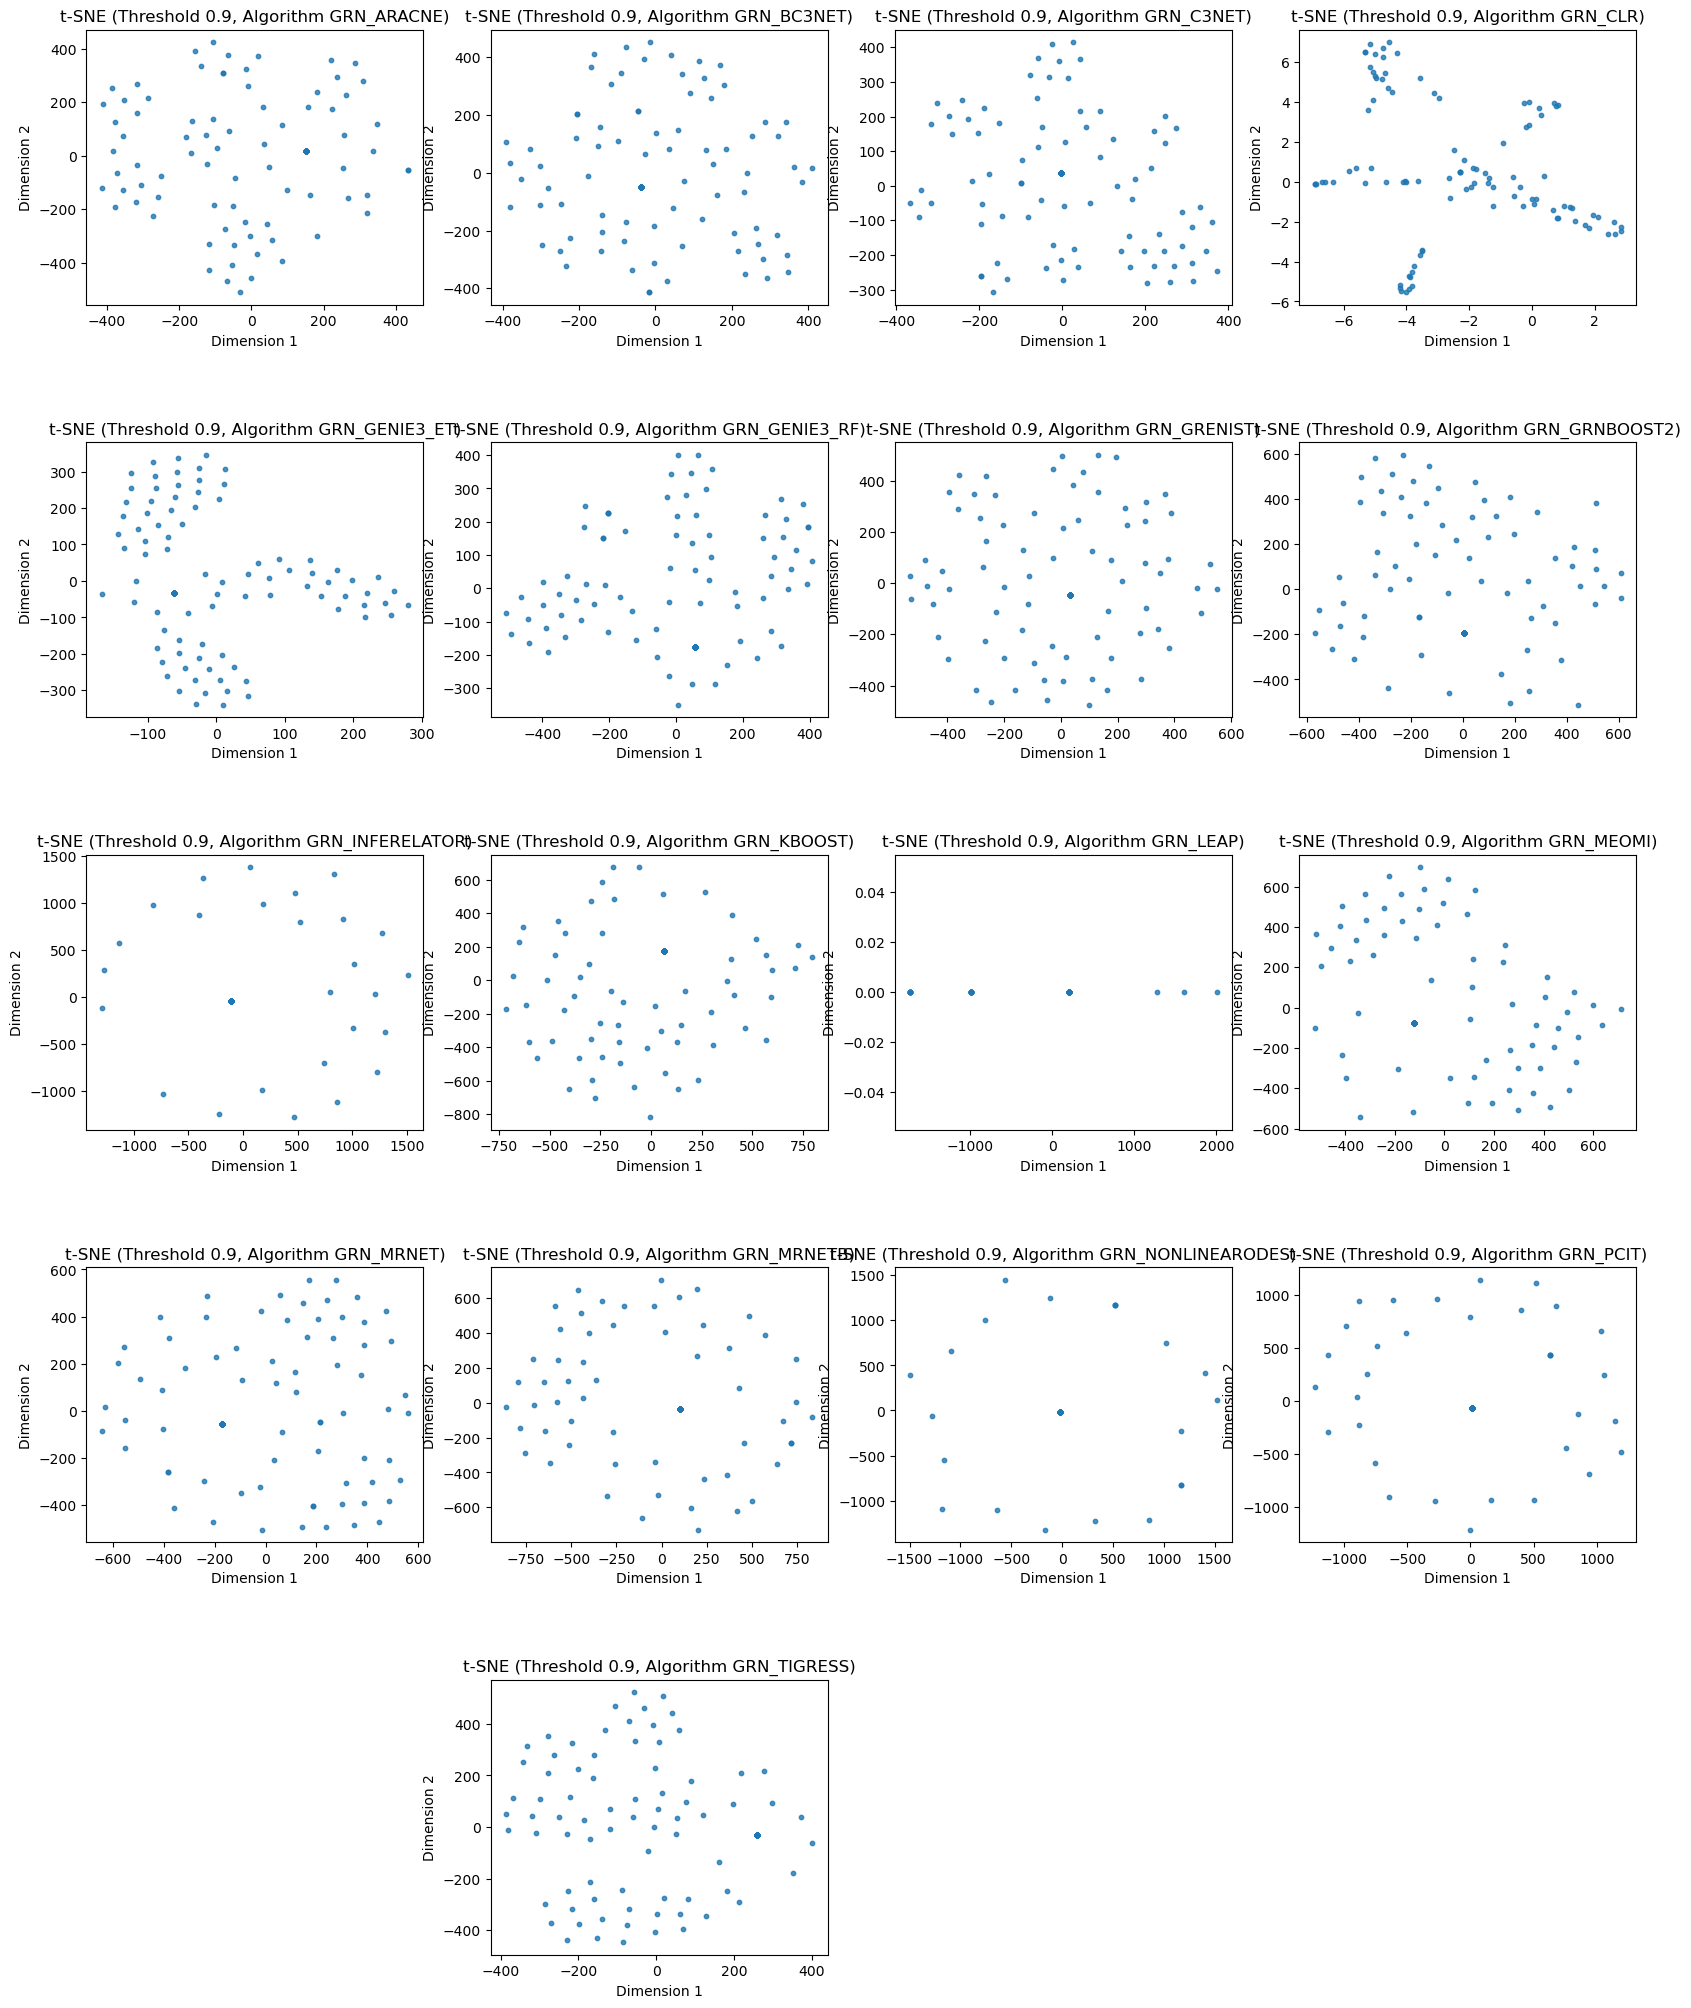

In [224]:
# Example: Extract embeddings for a specific threshold, algorithm, and iteration
#threshold = 0.2
#iteration = 7  # First iteration
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
import math

# Create a figure for all the plots
fig, axes = plt.subplots(5, 4, figsize=(20, 25))  # 5 rows, 4 columns
fig.subplots_adjust(hspace=0.5)  # Add space between rows

row, col = 0, 0  # Start with the first subplot

for idx, alg in enumerate(algorithms):
    if f'threshold_{threshold}' in embeddings and alg in embeddings[f'threshold_{threshold}']:
        z = embeddings[f'threshold_{threshold}'][alg][iteration]  # Extract embeddings
        
        # Perform t-SNE on z
        z_2d = TSNE(n_components=2, random_state=42).fit_transform(z)
        
        # Check if this is the last algorithm and center it in the last row
        if idx == len(algorithms) - 1:  # If it's the last algorithm
            row, col = 4, 1  # Place in the center of the last row

        # Plot the t-SNE visualization
        ax = axes[row, col]
        ax.scatter(z_2d[:, 0], z_2d[:, 1], s=10, alpha=0.8)
        ax.set_title(f"t-SNE (Threshold {threshold}, Algorithm {alg})")
        ax.set_xlabel("Dimension 1")
        ax.set_ylabel("Dimension 2")
        
        # Update the grid position
        if idx < len(algorithms) - 1:  # Skip for the last (centered) algorithm
            col += 1
            if col == 4:  # Move to the next row if column limit is reached
                col = 0
                row += 1
    else:
        print(f"Algorithm '{alg}' not found in embeddings for threshold {threshold}.")

# Hide empty subplots if necessary
for r in range(row, 5):  # Loop through rows
    for c in range(4):  # Loop through columns
        if r == 4 and c != 1:  # Leave the last row's middle position open
            axes[r, c].axis('off')  # Hide unused subplot areas

# Save the figure
plt.savefig("tsne_embeddings_grid.png", dpi=300, bbox_inches="tight")
plt.show()


In [225]:
# Initialize a list to store results for individual GRNs
individual_grn_results = []

# Iterate through each algorithm in the aggregated results
for threshold in thresholds:
    if f'threshold_{threshold}' not in aggregated_results:
        print(f"No results found for threshold {threshold}.")
        continue

    for alg in algorithms:
        if alg not in aggregated_results[f'threshold_{threshold}']:
            print(f"No results found for algorithm {alg} at threshold {threshold}.")
            continue
        
        # Access all binary adjacency matrices for this algorithm
        adjacency_matrices = aggregated_results[f'threshold_{threshold}'][alg]
        
        # Initialize a matrix to sum across iterations for consistency check
        summed_matrix = np.zeros_like(adjacency_matrices[0])
        
        # Iterate over all iterations for this algorithm
        for iteration_idx, binary_matrix in enumerate(adjacency_matrices):
            # Add this iteration's binary matrix to the summed matrix
            summed_matrix += binary_matrix
            
            # Extract nodes, edges, and interactions for this iteration
            num_nodes, num_edges = count_nodes_edges(binary_matrix)
            predicted_edges = extract_gene_interactions(binary_matrix, gene_names)
            
            # Store the result for this iteration
            individual_grn_results.append({
                'Algorithm': alg,
                'Threshold': threshold,
                'Iteration': iteration_idx + 1,
                'Nodes': num_nodes,
                'Edges': num_edges,
                'Gene_Interactions': ','.join(predicted_edges)  # Format G1-G2,G3-G4,...
            })
        
        # Optionally, apply a repetition threshold to filter nodes/edges
        # For example, keep only edges that appear in at least X iterations
        repetition_threshold = 5  # Set the minimum number of times an edge must appear
        final_filtered_matrix = (summed_matrix >= repetition_threshold).astype(int)
        num_nodes_filtered, num_edges_filtered = count_nodes_edges(final_filtered_matrix)
        filtered_edges = extract_gene_interactions(final_filtered_matrix, gene_names)
        
        # Store the filtered result for this algorithm
        individual_grn_results.append({
            'Algorithm': alg,
            'Threshold': threshold,
            'Iteration': 'Filtered',
            'Nodes': num_nodes_filtered,
            'Edges': num_edges_filtered,
            'Gene_Interactions': ','.join(filtered_edges)
        })

# Convert results into a DataFrame for easy visualization
individual_grn_results_df = pd.DataFrame(individual_grn_results)

# Save to CSV for further analysis
individual_grn_results_df.to_csv("individual_grn_results.csv", index=False)

# Display the DataFrame
individual_grn_results_df


,Algorithm,Threshold,Iteration,Nodes,Edges,Gene_Interactions
0,GRN_ARACNE,0.9,1,28,31,"G10-G72,G100-G2,G16-G17,G16-G28,G16-G51,G16-G5..."
1,GRN_ARACNE,0.9,2,38,35,"G1-G72,G10-G14,G10-G43,G14-G43,G16-G28,G16-G49..."
2,GRN_ARACNE,0.9,3,34,67,"G1-G29,G1-G37,G1-G69,G1-G72,G10-G14,G10-G43,G1..."
3,GRN_ARACNE,0.9,4,35,52,"G1-G31,G1-G59,G1-G60,G1-G68,G1-G69,G1-G73,G1-G..."
4,GRN_ARACNE,0.9,5,21,35,"G16-G18,G16-G22,G16-G47,G16-G52,G16-G53,G16-G5..."
...,...,...,...,...,...,...
182,GRN_TIGRESS,0.9,7,35,78,"G11-G15,G11-G99,G13-G22,G13-G46,G13-G57,G15-G2..."
183,GRN_TIGRESS,0.9,8,31,73,"G13-G22,G13-G57,G18-G22,G18-G46,G18-G47,G18-G4..."
184,GRN_TIGRESS,0.9,9,34,78,"G11-G99,G15-G99,G18-G22,G18-G46,G18-G47,G18-G5..."
185,GRN_TIGRESS,0.9,10,43,79,"G11-G15,G11-G5,G11-G99,G15-G5,G18-G22,G18-G46,..."


In [226]:
# Define the common threshold for filtering
#common_threshold = 7

# Initialize a dictionary to store edges and their counts for each algorithm
common_interactions = {}

# Iterate through each algorithm to count edge occurrences
for alg in individual_grn_results_df['Algorithm'].unique():
    # Filter the DataFrame for this algorithm
    alg_df = individual_grn_results_df[individual_grn_results_df['Algorithm'] == alg]
    
    # Initialize a dictionary to count edge occurrences
    edge_counts = {}
    
    for _, row in alg_df.iterrows():
        if row['Iteration'] != 'Filtered':  # Exclude already filtered rows if any
            # Get gene interactions for this iteration
            edges = row['Gene_Interactions'].split(',') if pd.notna(row['Gene_Interactions']) else []
            
            # Count occurrences of each edge
            for edge in edges:
                edge_counts[edge] = edge_counts.get(edge, 0) + 1
    
    # Filter edges that occur at least `common_threshold` times
    filtered_edges = [edge for edge, count in edge_counts.items() if count >= common_threshold]
    
    # Store the result for this algorithm
    common_interactions[alg] = filtered_edges

# Convert the results to a DataFrame for visualization or saving
common_interactions_df = pd.DataFrame([
    {'Algorithm': alg, 'Common_Interactions': ','.join(edges), 'Num_Common_Interactions': len(edges)}
    for alg, edges in common_interactions.items()
])

# Save the results to a CSV for further analysis
common_interactions_df.to_csv("common_interactions.csv", index=False)

# Display the DataFrame
common_interactions_df


,Algorithm,Common_Interactions,Num_Common_Interactions
0,GRN_ARACNE,G16-G53,1
1,GRN_BC3NET,"G18-G52,G18-G56,G22-G46,G22-G57,G42-G88,G50-G8...",10
2,GRN_C3NET,"G28-G78,G28-G79,G41-G50,G41-G90,G53-G57,G78-G7...",8
3,GRN_CLR,"G12-G88,G16-G22,G18-G22,G18-G46,G18-G47,G18-G5...",60
4,GRN_GENIE3_ET,"G15-G21,G15-G5,G15-G82,G15-G84,G15-G98,G15-G99...",31
5,GRN_GENIE3_RF,"G18-G22,G18-G46,G18-G47,G18-G49,G18-G52,G18-G5...",92
6,GRN_GRENIST,"G29-G37,G29-G69,G29-G72,G29-G74,G36-G98,G37-G6...",14
7,GRN_GRNBOOST2,"G20-G64,G20-G94,G23-G29,G23-G72,G23-G74,G29-G7...",19
8,GRN_INFERELATOR,,0
9,GRN_KBOOST,"G22-G57,G27-G30,G26-G30",3


In [227]:
# Normalize edges in the ground truth
normalized_known_edges = {normalize_edge(edge) for edge in known_edges}

# Initialize lists for storing the counts
true_positive_counts = []
false_positive_counts = []
false_negative_counts = []

# Iterate through each algorithm in common_interactions_df
for _, row in common_interactions_df.iterrows():
    # Extract algorithm name and common interactions
    alg = row['Algorithm']
    if pd.notna(row['Common_Interactions']):
        # Normalize the predicted common interactions
        predicted_edges = [normalize_edge(tuple(edge.split('-'))) for edge in row['Common_Interactions'].split(',')]
        predicted_edges_set = set(predicted_edges)

        # Calculate true positives, false positives, and false negatives
        true_positives = predicted_edges_set.intersection(normalized_known_edges)
        false_positives = predicted_edges_set.difference(normalized_known_edges)
        false_negatives = normalized_known_edges.difference(predicted_edges_set)

        # Append counts
        true_positive_counts.append(len(true_positives))
        false_positive_counts.append(len(false_positives))
        false_negative_counts.append(len(false_negatives))
    else:
        true_positive_counts.append(0)
        false_positive_counts.append(0)
        false_negative_counts.append(len(normalized_known_edges))  # All are false negatives if no predictions

# Add the counts to the DataFrame
common_interactions_df['True_Positives'] = true_positive_counts
common_interactions_df['False_Positives'] = false_positive_counts
common_interactions_df['False_Negatives'] = false_negative_counts

# Save the updated DataFrame to a CSV
common_interactions_df.to_csv("common_interactions_with_metrics.csv", index=False)

# Display the updated DataFrame
common_interactions_df


,Algorithm,Common_Interactions,Num_Common_Interactions,True_Positives,False_Positives,False_Negatives
0,GRN_ARACNE,G16-G53,1,0,1,168
1,GRN_BC3NET,"G18-G52,G18-G56,G22-G46,G22-G57,G42-G88,G50-G8...",10,1,9,167
2,GRN_C3NET,"G28-G78,G28-G79,G41-G50,G41-G90,G53-G57,G78-G7...",8,0,8,168
3,GRN_CLR,"G12-G88,G16-G22,G18-G22,G18-G46,G18-G47,G18-G5...",60,12,48,156
4,GRN_GENIE3_ET,"G15-G21,G15-G5,G15-G82,G15-G84,G15-G98,G15-G99...",31,6,25,162
5,GRN_GENIE3_RF,"G18-G22,G18-G46,G18-G47,G18-G49,G18-G52,G18-G5...",92,19,73,149
6,GRN_GRENIST,"G29-G37,G29-G69,G29-G72,G29-G74,G36-G98,G37-G6...",14,4,10,164
7,GRN_GRNBOOST2,"G20-G64,G20-G94,G23-G29,G23-G72,G23-G74,G29-G7...",19,2,17,166
8,GRN_INFERELATOR,,0,0,1,168
9,GRN_KBOOST,"G22-G57,G27-G30,G26-G30",3,1,2,167
